It is highly recommended to use a powerful **GPU**, you can use it for free uploading this notebook to [Google Colab](https://colab.research.google.com/notebooks/intro.ipynb).
<table align="center">
 <td align="center"><a target="_blank" href="https://colab.research.google.com/github/ezponda/intro_deep_learning/blob/main/class/CNN/Object_Detection_YOLO_ultralytics.ipynb">
        <img src="https://colab.research.google.com/img/colab_favicon_256px.png"  width="50" height="50" style="padding-bottom:5px;" />Run in Google Colab</a></td>
  <td align="center"><a target="_blank" href="https://github.com/ezponda/intro_deep_learning/blob/main/class/CNN/Object_Detection_YOLO_ultralytics.ipynb">
        <img src="https://github.githubassets.com/images/modules/logos_page/GitHub-Mark.png"  width="50" height="50" style="padding-bottom:5px;" />View Source on GitHub</a></td>
</table>

**Table of Contents**

* [Introduction to Ultralytics](#Introduction-to-Ultralytics)
* [Object Detection with Ultralytics using Pretrained YOLO Models](#Object-Detection-with-Ultralytics-using-Pretrained-YOLO-Models)
* [Non-Max Suppression (NMS) and Intersection Over Union (IoU)](#Non-Max-Suppression-(NMS)-and-Intersection-Over-Union-(IoU))
* [Webcam Local](#Web-cam-Local)
* [Different Vision Tasks](#YOLO-for-Different-Vision-Tasks)
* [Extra: Detecting Small Objects with SAHI](#Extra:-Detecting-Small-Objects-with-SAHI)

# Introduction to [Ultralytics](https://www.ultralytics.com/)

Ultralytics is a company that offers a variety of AI-based solutions, including the popular YOLO (You Only Look Once) object detection models. Their YOLO models are known for their speed and accuracy, making them suitable for real-time object detection tasks.

The Ultralytics framework provides a convenient and powerful platform for training, evaluating, and deploying object detection models. It is built on top of PyTorch and supports various YOLO versions.

For more detailed information and resources on Ultralytics, you can visit the [Ultralytics official documentation](https://docs.ultralytics.com/).



You can install it with:

```python
%pip install torch torchvision torchaudio
%pip install ultralytics
%pip install opencv-python
```

In [1]:
%pip install torch torchvision torchaudio
%pip install ultralytics
%pip install opencv-python
# For using the webcam:
%pip install lap
%pip install lapx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 42.3 MB/s eta 0:00:00


# Object Detection with Ultralytics using Pretrained YOLO Models


## Introduction to Object Detection

Object detection is a crucial area in computer vision, aiming to recognize and locate objects within images. It has vast applications in fields like autonomous driving, surveillance, and image retrieval.

## Introduction to YOLO (You Only Look Once)

YOLO is a real-time object detection system that applies a single neural network to the full image. This network divides the image into a grid and predicts bounding boxes and class probabilities for each grid cell.

The advantages of YOLO include:
- **Speed**: By processing the entire image in one evaluation, YOLO significantly reduces computational load, enabling real-time detection.
- **Accuracy**: Despite its speed, YOLO achieves high accuracy, particularly in detecting small objects.

## How Object Detection Works

Classification tells you **what** is in an image. Detection also tells you **where**: one bounding box per object, plus its class. There are two classic families of detectors.

**Two-stage detectors (the R-CNN family).** First a *region proposal* step suggests a few hundred candidate boxes that *might* contain something; then a second network classifies and refines each candidate.
*Intuition: "first spot the suspicious regions, then look at each one carefully."* Very accurate, but two passes → slow.

**Single-stage detectors (YOLO, SSD, RetinaNet).** A single network looks at the whole image **once** and predicts every box and class directly, in one forward pass.
*Intuition: "one glance, everything at once."* Much faster (real-time) — this is exactly what the name **You Only Look Once** refers to.

### How YOLO predicts — the intuition

YOLO splits the image into a grid of cells. For **each cell**, in a single pass, it predicts:

- **Bounding boxes** (x, y, width, height) — *where* an object is, relative to that cell.
- An **objectness score** — *"how sure am I there is an object here at all?"* This is what lets YOLO ignore empty background.
- **Class probabilities** — *"if there is an object here, what is it?"*

*Intuition:* every location in the image gets to "raise its hand" at the same time and say *"I think there's a dog here, at roughly this box, and I'm 90% sure."* All hands go up in one pass → real-time speed.

Because several neighbouring cells often fire for the **same** object, YOLO produces **duplicate boxes**. That is exactly why we need **Non-Max Suppression (NMS)** and **IoU** — covered in a later section — to keep only the best box per object.

### How it learns — briefly

YOLO is trained on images with ground-truth boxes by minimizing a **combined loss**:

- **Localization loss** — are the predicted box coordinates close to the true box? (often measured with IoU)
- **Objectness loss** — did it correctly flag which cells contain an object and which are background?
- **Classification loss** — is the predicted class correct?

*Intuition: reward good boxes on the right objects; punish boxes drawn on empty background or with the wrong label.*

In this notebook we won't train a detector from scratch (that needs a large dataset like COCO and a lot of compute). Instead we **use pretrained YOLO models** and focus on applying them. Note that YOLO / Ultralytics runs on **PyTorch**, unlike the TensorFlow/Keras used elsewhere in the course.


## Choosing the Pretrained YOLO Model

When selecting a pretrained model for your object detection tasks, it's essential to consider the balance between speed and accuracy. YOLO models come in different sizes to cater to a variety of requirements, from real-time applications to more accuracy-intensive tasks. These models have been trained on the COCO dataset, which is a benchmark in the object detection field.

### [COCO (Common Objects in Context)](https://cocodataset.org/#home)

- **Dataset Overview**: The COCO dataset is a comprehensive collection for object detection, segmentation, and captioning. It features over 200,000 images and 80 object categories, making it one of the most diverse datasets available.


### YOLO11 Model Variants

YOLO11 is the latest version from Ultralytics, offering improved accuracy and efficiency over previous versions.

| Model    | Size (pixels) | mAP<sub>val</sub> 50-95 | Speed (CPU ONNX, ms) | Speed (T4 TensorRT, ms) | Parameters (M) | FLOPs (B) |
|----------|---------------|------------------------|----------------------|-------------------------|----------------|-----------|
| yolo11n  | 640           | 39.5                   | 56.1                 | 1.5                     | 2.6            | 6.5       |
| yolo11s  | 640           | 47.0                   | 90.0                 | 2.5                     | 9.4            | 21.5      |
| yolo11m  | 640           | 51.5                   | 183.2                | 4.7                     | 20.1           | 68.0      |
| yolo11l  | 640           | 53.4                   | 238.6                | 6.2                     | 25.3           | 86.9      |
| yolo11x  | 640           | 54.7                   | 462.8                | 11.3                    | 56.9           | 194.9     |


### Understanding the Metrics

- **Size (pixels)**: The input resolution for the model.
- **mAP<sub>val</sub> 50-95**: The mean Average Precision on the COCO validation dataset, covering IoU thresholds from 0.5 to 0.95. Higher values indicate better accuracy.
- **Speed**: Inference speed measured in milliseconds. Lower times indicate faster performance.
- **Parameters (M)**: The number of trainable parameters in millions.
- **FLOPs (B)**: Floating Point Operations in billions. Higher values indicate more computational complexity.

When choosing a model, consider the trade-off between speed and accuracy. Smaller models like `yolo11n` are faster but less accurate, suitable for real-time applications. Larger models like `yolo11x` provide higher accuracy at the cost of increased inference time.

In [2]:
from ultralytics import YOLO
import numpy as np

model = YOLO('yolo11n.pt')  # load a pretrained YOLO11n detection model

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


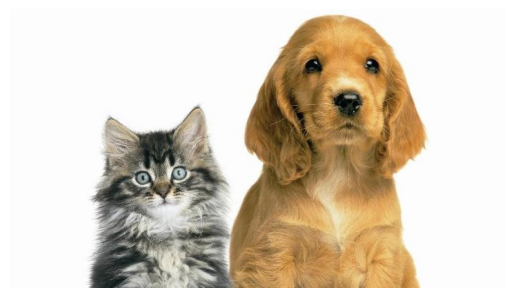

In [3]:
from matplotlib import pyplot as plt
import urllib
import numpy as np
import cv2
import time

url = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/dog_cat.jpg'
image_path = "dog-cat.jpg"
urllib.request.urlretrieve(url, image_path)

# Read the image in color mode (OpenCV loads as BGR)
image = cv2.imread(image_path, cv2.IMREAD_COLOR)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


plt.imshow(image_rgb)
plt.axis('off')
plt.show()

In [4]:
results = model(image)
print('Results:\n')
print(results)


0: 384x640 1 cat, 1 dog, 8.7ms
Speed: 93.7ms preprocess, 8.7ms inference, 38.0ms postprocess per image at shape (1, 3, 384, 640)
Results:

[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: '

In [5]:
results[0].names

{0: 'person',
 1: 'bicycle',
 2: 'car',
 3: 'motorcycle',
 4: 'airplane',
 5: 'bus',
 6: 'train',
 7: 'truck',
 8: 'boat',
 9: 'traffic light',
 10: 'fire hydrant',
 11: 'stop sign',
 12: 'parking meter',
 13: 'bench',
 14: 'bird',
 15: 'cat',
 16: 'dog',
 17: 'horse',
 18: 'sheep',
 19: 'cow',
 20: 'elephant',
 21: 'bear',
 22: 'zebra',
 23: 'giraffe',
 24: 'backpack',
 25: 'umbrella',
 26: 'handbag',
 27: 'tie',
 28: 'suitcase',
 29: 'frisbee',
 30: 'skis',
 31: 'snowboard',
 32: 'sports ball',
 33: 'kite',
 34: 'baseball bat',
 35: 'baseball glove',
 36: 'skateboard',
 37: 'surfboard',
 38: 'tennis racket',
 39: 'bottle',
 40: 'wine glass',
 41: 'cup',
 42: 'fork',
 43: 'knife',
 44: 'spoon',
 45: 'bowl',
 46: 'banana',
 47: 'apple',
 48: 'sandwich',
 49: 'orange',
 50: 'broccoli',
 51: 'carrot',
 52: 'hot dog',
 53: 'pizza',
 54: 'donut',
 55: 'cake',
 56: 'chair',
 57: 'couch',
 58: 'potted plant',
 59: 'bed',
 60: 'dining table',
 61: 'toilet',
 62: 'tv',
 63: 'laptop',
 64: 'mou

In [6]:
print(results[0].boxes)

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([16., 15.], device='cuda:0')
conf: tensor([0.9481, 0.8671], device='cuda:0')
data: tensor([[338.8131,   9.2517, 647.0267, 429.1023,   0.9481,  16.0000],
        [119.6808, 148.4938, 347.3080, 430.1570,   0.8671,  15.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (433, 770)
shape: torch.Size([2, 6])
xywh: tensor([[492.9199, 219.1770, 308.2136, 419.8506],
        [233.4944, 289.3254, 227.6272, 281.6631]], device='cuda:0')
xywhn: tensor([[0.6402, 0.5062, 0.4003, 0.9696],
        [0.3032, 0.6682, 0.2956, 0.6505]], device='cuda:0')
xyxy: tensor([[338.8131,   9.2517, 647.0267, 429.1023],
        [119.6808, 148.4938, 347.3080, 430.1570]], device='cuda:0')
xyxyn: tensor([[0.4400, 0.0214, 0.8403, 0.9910],
        [0.1554, 0.3429, 0.4510, 0.9934]], device='cuda:0')


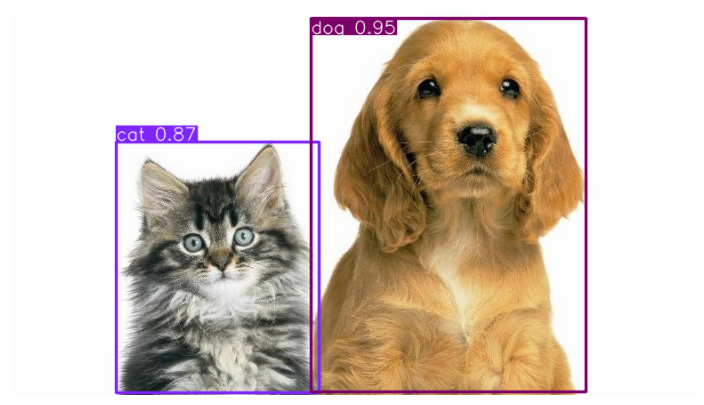

In [7]:
for r in results:
    # Extract the original and annotated images
    original_img = r.orig_img[..., ::-1]
    annotated_image_bgr = r.plot()  # BGR numpy array of predictions
    annotated_image_rgb = annotated_image_bgr[..., ::-1]  # Convert BGR to RGB

    # Plot the annotated image
    plt.figure(figsize=(9, 5))
    plt.imshow(annotated_image_rgb) # RGB PIL image
    plt.axis('off')
    plt.show()

In [8]:
import urllib
import cv2
from matplotlib import pyplot as plt

def download_images(image_urls, plot_images=False):
    """
    Downloads images from the given URLs, converts them to RGB format, and optionally plots them.

    Args:
    image_urls (list of tuples): A list where each tuple contains the image URL and the desired local file path.
    plot_images (bool): If True, the images will be plotted. Defaults to False.

    Returns:
    list: A list of paths where the images have been saved.
    """
    image_paths = []  # Store the local file paths of the images

    for image_url, image_path in image_urls:
        # Download the image from the URL and save it to the local file path
        urllib.request.urlretrieve(image_url, image_path)
        image_paths.append(image_path)  # Add the local file path to the list

        if plot_images:
            # Read the image in color mode
            image = cv2.imread(image_path, cv2.IMREAD_COLOR)
            # Convert the image from BGR to RGB format
            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Plot the image
            plt.figure(figsize=(8, 4))
            plt.imshow(image_rgb)  # Display the image in RGB format
            plt.axis('off')  # Turn off axis labels and ticks
            plt.title(image_path)  # Set the title of the plot as the image path
            plt.show()  # Display the plot

    return image_paths


In [9]:
import ssl

ssl._create_default_https_context = ssl._create_unverified_context


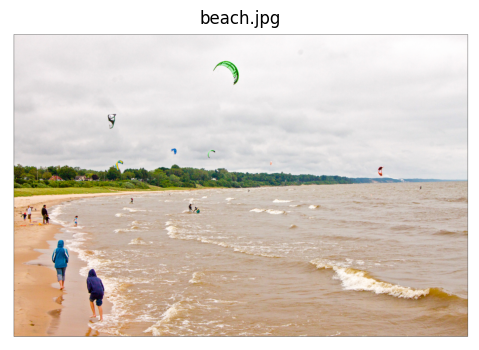

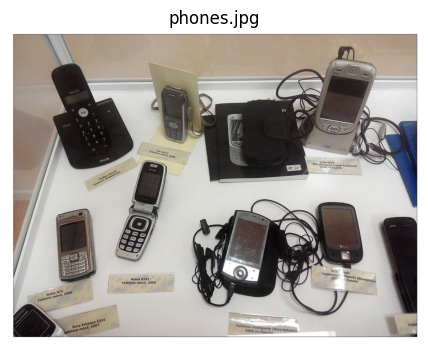

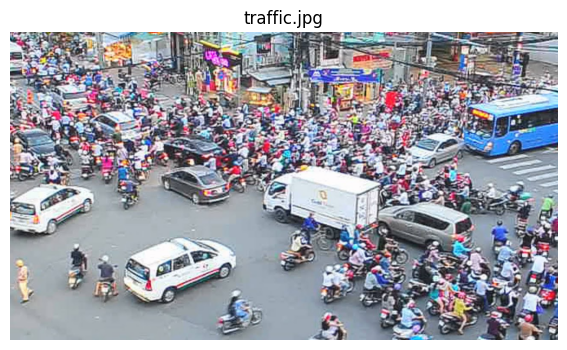

In [10]:
image_urls = [
    ('https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/beach.jpg', 'beach.jpg'),
    ('https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/phones.jpg', 'phones.jpg'),
    ('https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/traffic.jpg', 'traffic.jpg')
]

image_paths = download_images(image_urls, plot_images=True)


0: 640x640 10 persons, 4 kites, 14.0ms
1: 640x640 10 cell phones, 14.0ms
2: 640x640 3 persons, 6 cars, 3 motorcycles, 2 buss, 1 truck, 14.0ms
Speed: 1.8ms preprocess, 14.0ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)


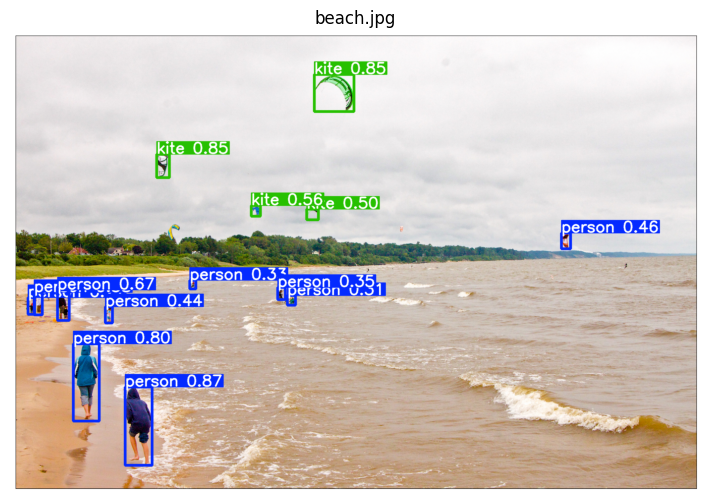

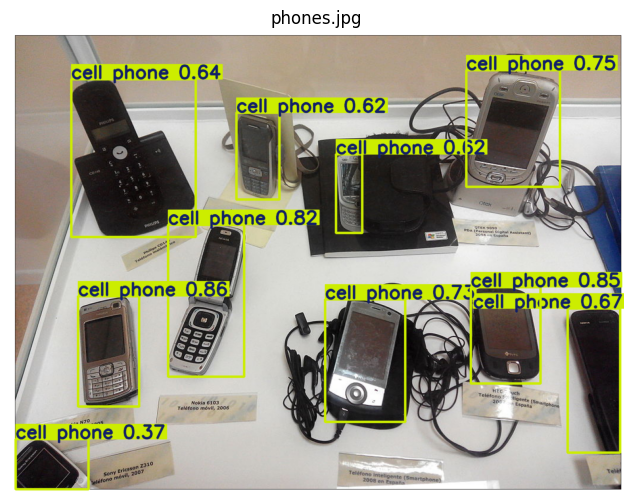

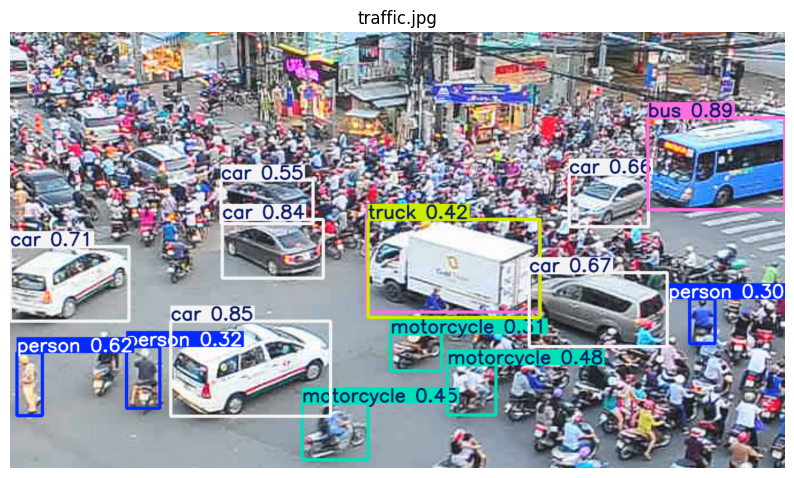

In [11]:
# Run the model
results = model(image_paths)

# Show results
for i, r in enumerate(results):
    # Extract the original and annotated images
    original_img = r.orig_img[..., ::-1]
    annotated_image_bgr = r.plot()  # BGR numpy array of predictions
    annotated_image_rgb = annotated_image_bgr[..., ::-1]  # Convert BGR to RGB

    # Plot the annotated image
    plt.figure(figsize=(10, 6))
    plt.imshow(annotated_image_rgb) # RGB PIL image
    plt.axis('off')
    plt.title(image_paths[i])
    plt.show()


### Compare different models

Model Comparison Summary:
------------------------------------------------------------
Model        | Detections | Inference Time (ms) 
------------------------------------------------------------

0: 384x640 2 persons, 6 cars, 2 motorcycles, 2 buss, 1 truck, 8.0ms
Speed: 1.9ms preprocess, 8.0ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)
yolo11n.pt   | 13         | 101.9

0: 384x640 1 person, 5 cars, 2 motorcycles, 1 bus, 1 truck, 16.1ms
Speed: 2.9ms preprocess, 16.1ms inference, 1.7ms postprocess per image at shape (1, 3, 384, 640)
yolo11s.pt   | 10         | 172.2

0: 384x640 2 persons, 5 cars, 4 motorcycles, 1 bus, 1 truck, 34.8ms
Speed: 3.3ms preprocess, 34.8ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)
yolo11m.pt   | 13         | 253.9


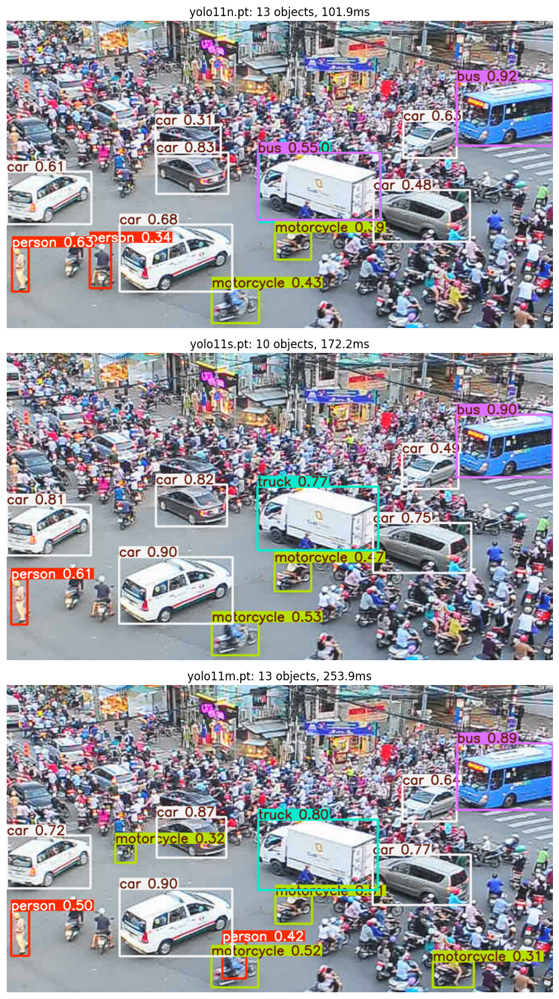

In [12]:
from typing import List
def compare_models(image_path: str, model_names: List[str], conf_threshold: float=0.25):
    """
    Simple function to compare different YOLO models on the same image.
    """

    # Read the image
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Set up plot
    fig, axs = plt.subplots(len(model_names), 1, figsize=(10, 5 * len(model_names)))
    if len(model_names) == 1:
        axs = [axs]  # Make it iterable if only one model

    # Print summary header
    print("Model Comparison Summary:")
    print("-" * 60)
    print(f"{'Model':<12} | {'Detections':<10} | {'Inference Time (ms)':<20}")
    print("-" * 60)

    # Process each model
    for i, model_name in enumerate(model_names):
        # Load model
        model = YOLO(model_name)

        # Measure inference time
        start_time = time.time()
        results = model(img_rgb, conf=conf_threshold)
        inference_time = (time.time() - start_time) * 1000  # ms

        # Get detection count
        num_detections = len(results[0].boxes)

        # Plot results
        axs[i].imshow(results[0].plot())
        axs[i].set_title(f"{model_name}: {num_detections} objects, {inference_time:.1f}ms", fontsize=12)
        axs[i].axis('off')

        # Print summary line
        print(f"{model_name:<12} | {num_detections:<10} | {inference_time:.1f}")

    plt.tight_layout()
    plt.show()

compare_models('traffic.jpg', ["yolo11n.pt", "yolo11s.pt", "yolo11m.pt"], conf_threshold=0.3)

### Non-Max Suppression (NMS) and Intersection Over Union (IoU)

Object detection models often detect multiple bounding boxes around the same object. This leads to redundant detections for the same object, which is undesirable. To resolve this, two key concepts are utilized: Intersection Over Union (IoU) and Non-Max Suppression (NMS). These techniques help refine the boxes surrounding detected objects, ensuring each object is identified accurately and uniquely.

#### Intersection Over Union (IoU)

IoU is a metric used to quantify the percent overlap between two bounding boxes. It is calculated by dividing the area of overlap between the two boxes by the area of their union:

\begin{equation*}
\text{IoU} = \frac{\text{Area of Overlap}}{\text{Area of Union}}
\end{equation*}

For object detection, IoU is utilized to determine how close a predicted bounding box is to the ground truth bounding box. During evaluation, a higher IoU represents a better prediction by the model.

However, in the context of running inference with a model, IoU is crucial for Non-Max Suppression.

#### Non-Max Suppression (NMS)

Non-Max Suppression is a technique to ensure that only the most probable bounding box for an object is preserved while all other redundant boxes are removed. Here's how it generally works:

1. Select the box with the highest probability of object detection (confidence score).
2. Compute the IoU of this box with all other boxes. If any box has an IoU greater than a set threshold (typically between 0.5 and 0.7), it is suppressed (i.e., removed).
3. Repeat this process for all boxes until each detected object is represented by only one box.

NMS ensures that in cases where multiple boxes predict the same object, only the most accurate one is kept.

#### Usage in Ultralytics YOLO Inference

When you run inference using the Ultralytics YOLO model, you can control the behavior of NMS and IoU through the inference arguments:

- `conf`: This is the confidence threshold. Detections with a confidence score below this threshold are disregarded before NMS. By adjusting this value, you can filter out weak detections early. **(default 0.25)**
- `iou`: This is the IoU threshold for NMS. In areas where multiple bounding boxes overlap, if the overlap (IoU) is greater than this threshold, only the box with the highest confidence is kept. **(default 0.7)**

**What happens at the extremes?**

- **`iou` → 0 (aggressive NMS):** almost *any* overlap counts as a duplicate, so overlapping boxes get suppressed. You keep **fewer** boxes and may even merge distinct objects that are close together. **`iou` → 1 (almost no NMS):** boxes are suppressed only if they overlap almost perfectly, so you keep **more** boxes — including **duplicate** boxes on the same object.
- **`conf` → 0:** even very uncertain detections survive → **more** boxes, but more false positives. **`conf` → 1:** only very confident detections survive → **fewer** boxes, but you may miss real objects.

Here is how you can use these parameters in practice:

```python
from ultralytics import YOLO

# Load a pretrained YOLO model
model = YOLO('yolo11n.pt')

# Run inference with custom confidence and IoU thresholds
results = model.predict(image, conf=0.25, iou=0.7)
```

#### Visualizing IoU

Let's implement and visualize IoU to build intuition:

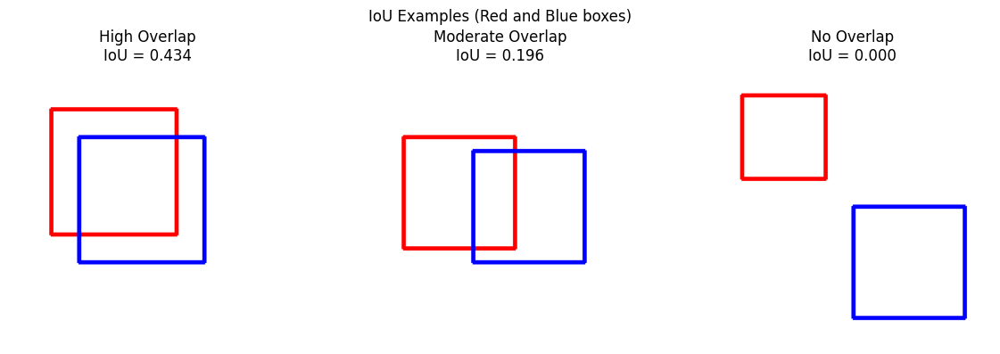

In [13]:
## IoU visualization with different overlap levels
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Example boxes: [x1, y1, x2, y2]
examples = [
    ([30, 30, 120, 120], [50, 50, 140, 140], "High Overlap"),
    ([30, 50, 110, 130], [80, 60, 160, 140], "Moderate Overlap"),
    ([20, 20, 80, 80], [100, 100, 180, 180], "No Overlap"),
]

for ax, (box1, box2, title) in zip(axes, examples):
    img = np.ones((200, 200, 3), dtype=np.uint8) * 255
    cv2.rectangle(img, (box1[0], box1[1]), (box1[2], box1[3]), (255, 0, 0), 2)
    cv2.rectangle(img, (box2[0], box2[1]), (box2[2], box2[3]), (0, 0, 255), 2)

    # Calculate IoU
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter_area = max(0, x2-x1) * max(0, y2-y1)
    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])
    iou = inter_area / (area1 + area2 - inter_area)

    ax.imshow(img)
    ax.set_title(f"{title}\nIoU = {iou:.3f}")
    ax.axis("off")

plt.suptitle("IoU Examples (Red and Blue boxes)")
plt.tight_layout()
plt.show()

#### NMS Example

Let's visualize how NMS removes duplicate detections:

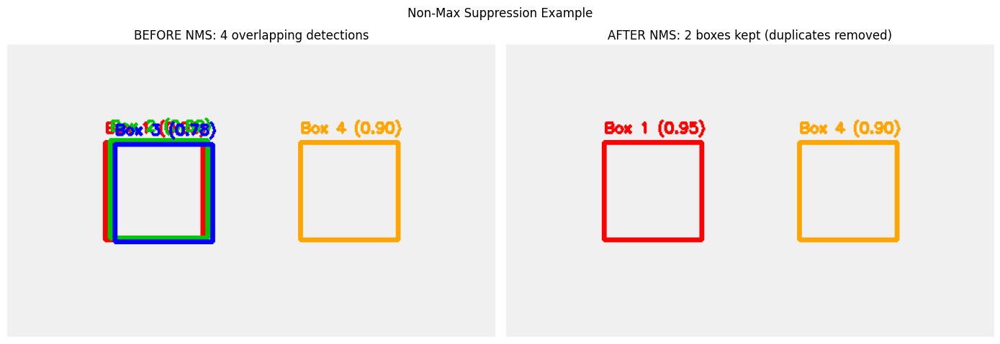

In [14]:
## Simulated overlapping detections for the same object
fake_boxes = [
    {"id": 1, "box": [100, 100, 200, 200], "conf": 0.95},  # Highest confidence
    {"id": 2, "box": [105, 98, 205, 198], "conf": 0.82},   # Overlaps with box 1
    {"id": 3, "box": [110, 102, 210, 202], "conf": 0.78},  # Overlaps with box 1
    {"id": 4, "box": [300, 100, 400, 200], "conf": 0.90},  # Different object
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = [(255, 0, 0), (0, 200, 0), (0, 0, 255), (255, 165, 0)]

## Before NMS: all boxes
img_before = np.ones((300, 500, 3), dtype=np.uint8) * 240
for i, det in enumerate(fake_boxes):
    box = det["box"]
    cv2.rectangle(img_before, (box[0], box[1]), (box[2], box[3]), colors[i], 3)
    cv2.putText(img_before, f"Box {det['id']} ({det['conf']:.2f})",
                (box[0], box[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colors[i], 2)

axes[0].imshow(img_before)
axes[0].set_title("BEFORE NMS: 4 overlapping detections")
axes[0].axis("off")

## After NMS: only kept boxes (Box 1 highest conf, Box 4 different object)
img_after = np.ones((300, 500, 3), dtype=np.uint8) * 240
kept = [fake_boxes[0], fake_boxes[3]]
for det, color in zip(kept, [colors[0], colors[3]]):
    box = det["box"]
    cv2.rectangle(img_after, (box[0], box[1]), (box[2], box[3]), color, 3)
    cv2.putText(img_after, f"Box {det['id']} ({det['conf']:.2f})",
                (box[0], box[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

axes[1].imshow(img_after)
axes[1].set_title("AFTER NMS: 2 boxes kept (duplicates removed)")
axes[1].axis("off")

plt.suptitle("Non-Max Suppression Example")
plt.tight_layout()
plt.show()

#### Question 1: Change confidence and IoU thresholds for detecting more objects

In [ ]:
# Run the model
results = model(image_paths, conf=..., iou=...)

# Show results
for r in results:
    # Extract the original and annotated images
    original_img = r.orig_img[..., ::-1]
    annotated_image_bgr = r.plot()  # BGR numpy array of predictions
    annotated_image_rgb = annotated_image_bgr[..., ::-1]  # Convert BGR to RGB

    # Plot the annotated image
    plt.figure(figsize=(10, 6))
    plt.imshow(annotated_image_rgb) # RGB PIL image
    plt.axis('off')
    plt.show()

## Webcam Local

> **Note**: This section requires a local environment with webcam access. It will not work in Google Colab.

### Detection loop

The detection loop consists of:

- Loading the webcam frame
- Running the image through the model
- Updating the output with the resulting predictions

In [16]:
from PIL import Image
from IPython.display import Image as IPyImage
from google.colab.patches import cv2_imshow
import time
import numpy as np
import cv2

cap = cv2.VideoCapture(0)
time.sleep(1)  ### letting the camera autofocus

axes = None
NUM_FRAMES = 50  # you can change this
processed_imgs = []
for i in range(NUM_FRAMES):
    # Load frame from the camera
    ret, frame = cap.read()
    if not ret:
        break

    # Run the model
    result = model(frame, verbose=False)
    annotated_image_bgr = result[0].plot()
    annotated_image_rgb = annotated_image_bgr[:,:, ::-1]  # Convert BGR to RGB

    img = Image.fromarray(np.uint8(annotated_image_rgb))
    processed_imgs.append(img)
    # Use Colab's patch instead of cv2.imshow
    cv2_imshow(annotated_image_bgr)
    cv2.waitKey(1)

cap.release()
cv2.destroyAllWindows()

In [18]:
## create gif
if len(processed_imgs) > 0:
    processed_imgs[0].save('web_cam.gif',
                           format='GIF',
                           append_images=processed_imgs[1:],
                           save_all=True,
                           duration=100,
                           loop=0)
    print("GIF guardado correctamente como 'web_cam.gif'.")
else:
    print("Error: No se pudo crear el GIF porque 'processed_imgs' está vacío. Esto ocurre porque la webcam no está disponible en este entorno.")

Error: No se pudo crear el GIF porque 'processed_imgs' está vacío. Esto ocurre porque la webcam no está disponible en este entorno.


In [ ]:
# IPyImage('web_cam.gif', format='png', width=15 * 40, height=3 * 40)

## Question 2: Traffic Scene  Object Detection

In [19]:
## load the scene gif
url_1 = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/scene1.gif'
scene_1_path = 'scene_1.gif'
urllib.request.urlretrieve(url_1, scene_1_path)

('scene_1.gif', <http.client.HTTPMessage at 0x7e601ebb9130>)

In [20]:
# IPyImage(scene_1_path, format='png', width=15 * 40, height=3 * 40)
IPyImage(url=url_1)

In [21]:
model = YOLO('yolo11x.pt')  # load a pretrained YOLO11x detection model

In [22]:
from tqdm import tqdm

gif_object = Image.open(scene_1_path)

# Display individual frames from the loaded animated GIF file
processed_imgs = []
for _, ind in tqdm(enumerate(range(0, gif_object.n_frames))):
    gif_object.seek(ind)
    ## frame in numpy array format (512, 512, 3)
    frame = np.array(gif_object.convert('RGB'))[:,:,::-1]

    ## Object Detection code
    ...

    img = Image.fromarray(np.uint8(annotated_image_rgb))
    processed_imgs.append(img)

103it [00:02, 43.95it/s]


In [23]:
## save the processed scene gif
processed_imgs[0].save('scene1_boxes.gif',
                       format='GIF',
                       append_images=processed_imgs[1:],
                       save_all=True,
                       duration=200,
                       loop=0)

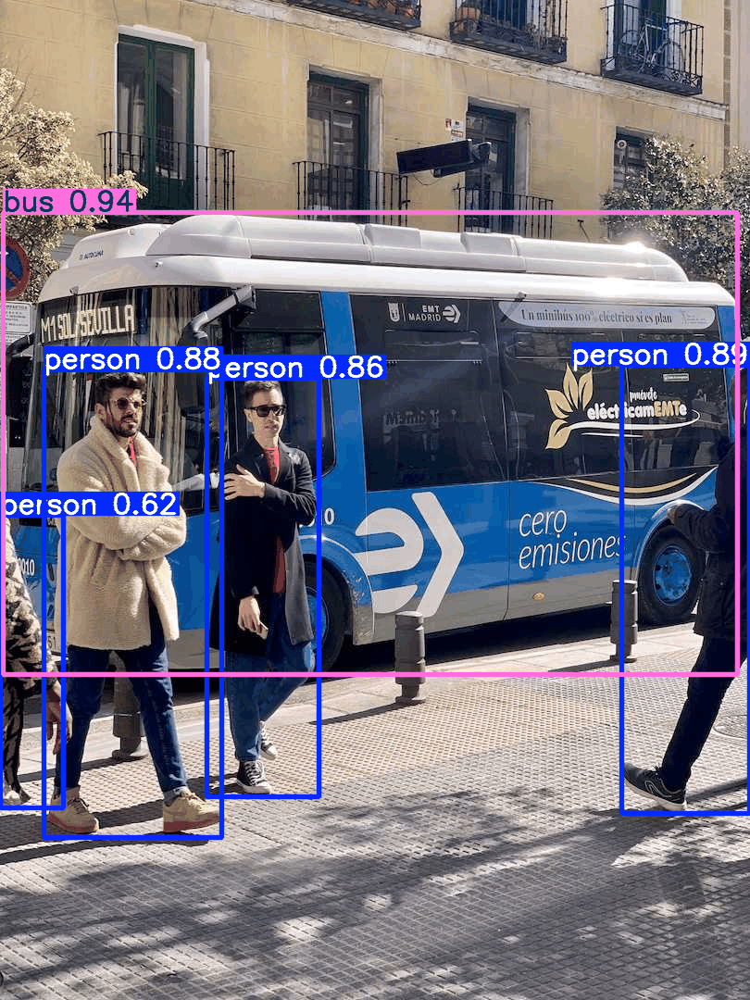

In [24]:
IPyImage('scene1_boxes.gif', format='png', width=15 * 40, height=3 * 40)

## YOLO for Different Vision Tasks

###  Segmentation

Segmentation models, indicated by the `-seg` suffix (e.g., `yolo11n-seg.pt`), are designed for more detailed analysis. These models not only detect objects but also delineate their exact shapes, segmenting each object from the background and other objects.

In [25]:
model = YOLO('yolo11n-seg.pt')


image 1/1 /content/traffic.jpg: 384x640 4 persons, 5 cars, 1 motorcycle, 2 buss, 11.1ms
Speed: 1.5ms preprocess, 11.1ms inference, 34.9ms postprocess per image at shape (1, 3, 384, 640)


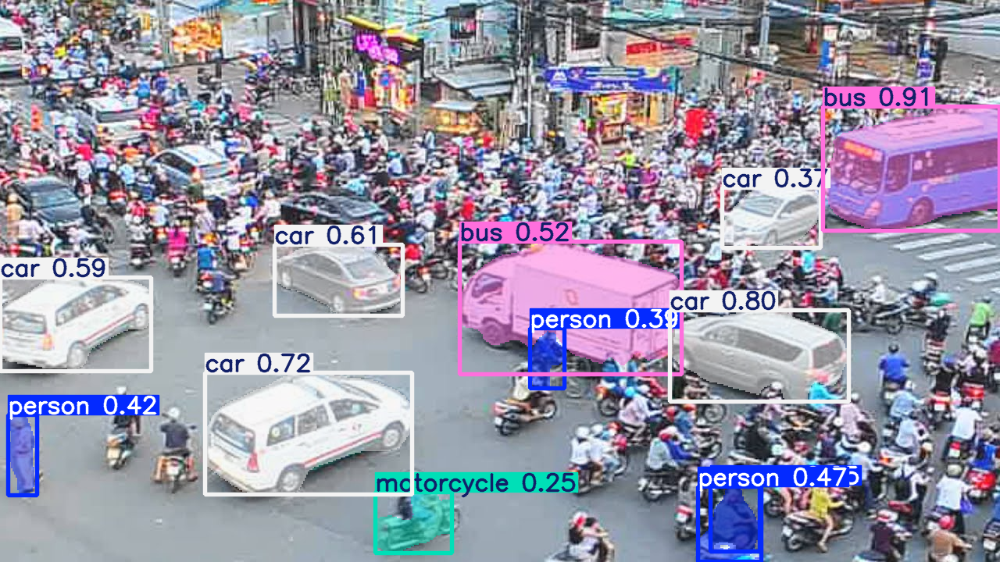

In [26]:
results = model('traffic.jpg')
results[0].show()  # Display the segmentation results

In [27]:
from ultralytics.engine.results import Results

def extract_segmentation_mask(
    detection_result: Results,
    object_index: int = 0
) -> np.ndarray:
    """
    Extracts a binary segmentation mask for a specific detected object.

    This function creates a precise binary mask from YOLO segmentation contours
    where white pixels (255) represent the object and black pixels (0) represent
    the background.

    Parameters:
        detection_result: The YOLO Results object containing segmentation data
        object_index: The index of the object to extract (0 for first detection)

    Returns:
        A binary mask as a NumPy array of type uint8
    """
    # Verify the inputs
    if detection_result.masks is None:
        raise ValueError("No segmentation masks found in detection results")

    if object_index >= len(detection_result.masks.xy):
        raise IndexError(f"Object index {object_index} is out of range. "
                         f"Only {len(detection_result.masks.xy)} objects detected.")

    # Get original image dimensions
    height, width = detection_result.orig_img.shape[:2]

    # Create an empty mask with the original image dimensions
    binary_mask = np.zeros((height, width), dtype=np.uint8)

    # Get the contour points from the detection result
    contour_points = detection_result.masks.xy[object_index]

    # Format the contour for OpenCV's drawContours function
    formatted_contour = contour_points.astype(np.int32).reshape(-1, 1, 2)

    # Draw the filled contour onto the empty mask
    cv2.drawContours(binary_mask, [formatted_contour], -1, 255, cv2.FILLED)

    # Convert the mask to a binary format
    binary_mask = binary_mask.astype(bool)

    return binary_mask

__________________________________________________
bus


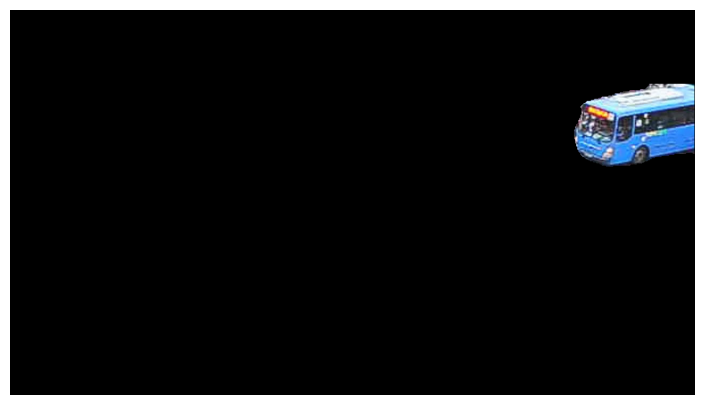

__________________________________________________
car


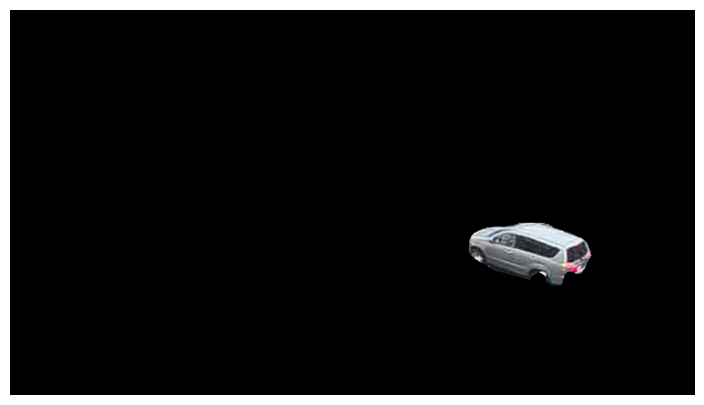

In [28]:
result = results[0]
img = cv2.cvtColor(result.orig_img, cv2.COLOR_BGR2RGB)

for object_index in range(len(result.boxes.cls.tolist())):
    if object_index == 2:
        break
    # Get class label
    label = result.names[result.boxes.cls.tolist()[object_index]]
    print('_'*50)
    print(label)

    # Create the binary mask for the object
    b_mask = extract_segmentation_mask(result, object_index)

    # Create the isolated image from the binary b_mask
    masked_img = img.copy()
    # Set background to black
    masked_img[~b_mask] = 0

    plt.figure(figsize=(9, 5))
    plt.imshow(masked_img)
    plt.axis('off')
    plt.show()

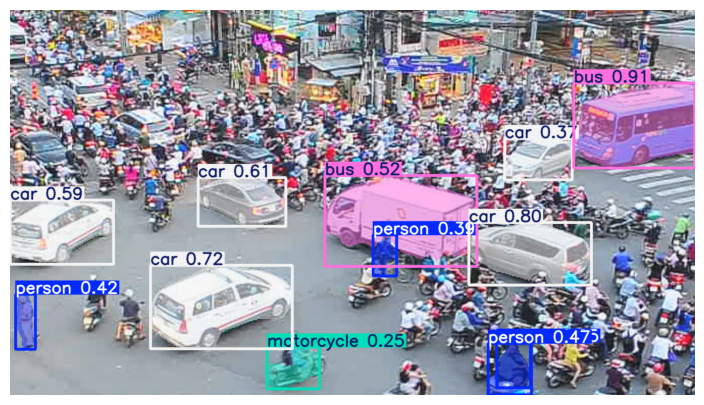

In [29]:
annotated_image_bgr = result.plot()  # BGR numpy array of predictions
annotated_image_rgb = annotated_image_bgr[..., ::-1]  # Convert BGR to RGB

# Plot the annotated image
plt.figure(figsize=(9, 5))
plt.imshow(annotated_image_rgb)
plt.axis('off')
plt.show()

#### Working with Segmentation Masks: Visualization and Manipulation

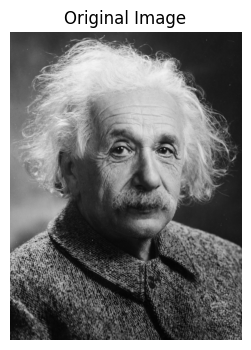

In [30]:
url = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/albert_einstein.jpg'
image_path = 'einstein.jpg'
urllib.request.urlretrieve(url, image_path)

# Load and display image
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(4, 4))
plt.imshow(image_rgb)
plt.axis('off')
plt.title('Original Image')
plt.show()


0: 640x480 1 person, 19.5ms
Speed: 3.1ms preprocess, 19.5ms inference, 20.5ms postprocess per image at shape (1, 3, 640, 480)


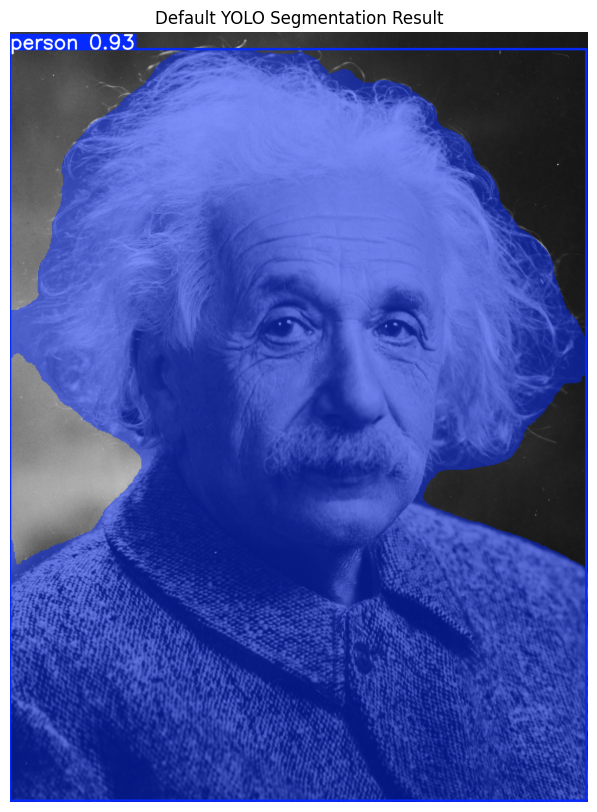

In [31]:
# Run segmentation
results = model(image, conf=0.3)  # Lower confidence threshold for our example
result = results[0]

# Display the default visualization
annotated = result.plot()[..., ::-1]  # Convert BGR to RGB
plt.figure(figsize=(10, 10))
plt.imshow(annotated)
plt.axis('off')
plt.title('Default YOLO Segmentation Result')
plt.show()

##### Explore the Segmentation Data Structure

In [32]:
print("Available attributes in result:")
print(dir(result))

# Check mask information
if result.masks is not None:
    print("\nMask information:")
    print(f"Number of masks: {len(result.masks)}")
    print(f"Shape of first mask: {result.masks.data[0].shape}")
    print(f"Data type: {result.masks.data[0].dtype}")

    # Get class information
    if len(result.boxes) > 0:
        print("\nDetected classes:")
        for i, box in enumerate(result.boxes):
            class_id = int(box.cls)
            class_name = result.names[class_id]
            confidence = float(box.conf)
            print(f"Object {i+1}: {class_name} (Confidence: {confidence:.2f})")

Available attributes in result:
['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_apply', '_keys', 'boxes', 'cpu', 'cuda', 'depth', 'keypoints', 'masks', 'names', 'new', 'numpy', 'obb', 'orig_img', 'orig_shape', 'path', 'plot', 'probs', 'save', 'save_crop', 'save_dir', 'save_txt', 'semantic_mask', 'show', 'speed', 'summary', 'to', 'to_csv', 'to_df', 'to_json', 'update', 'verbose']

Mask information:
Number of masks: 1
Shape of first mask: torch.Size([640, 480])
Data type: torch.uint8

Detected classes:
Object 1: person (Confidence: 0.93)


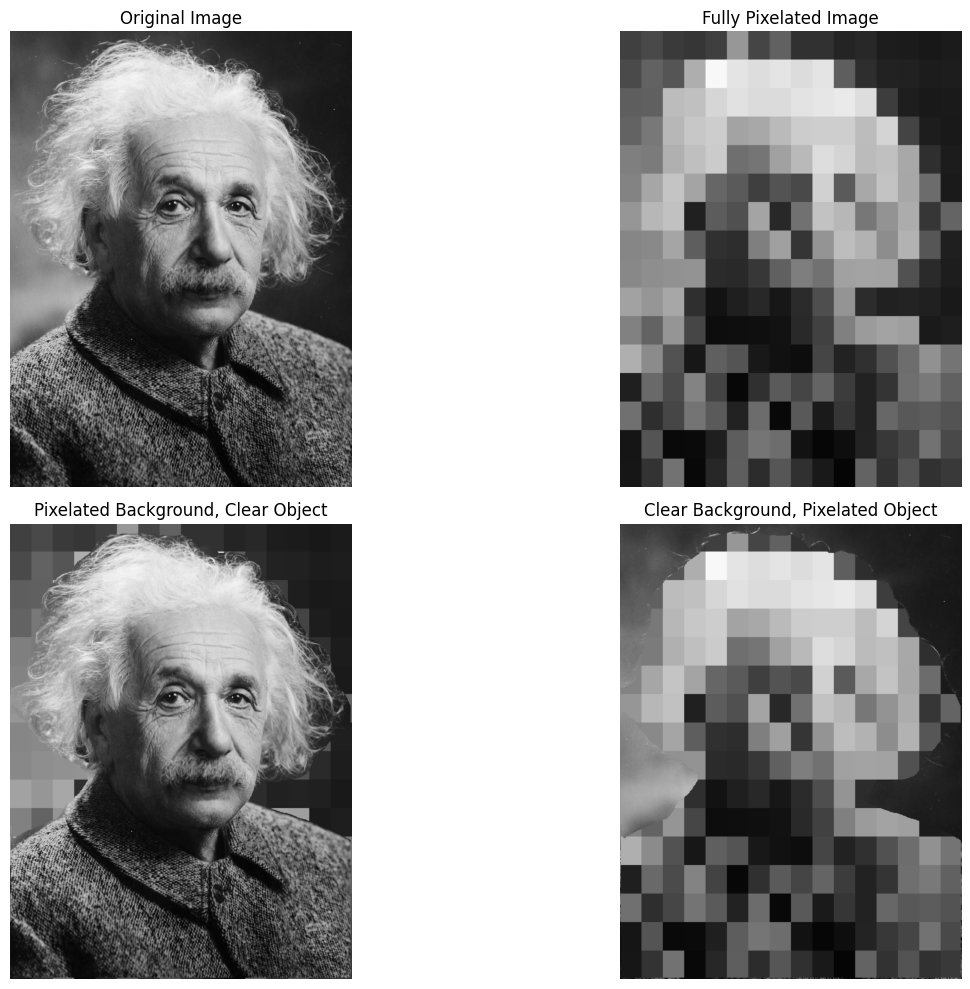

In [33]:
def pixelate(image, blocks=16):
    """Heavily pixelate an image region by downsampling and upsampling"""
    # Get dimensions
    h, w = image.shape[:2]

    # Downsample
    temp = cv2.resize(image, (blocks, blocks), interpolation=cv2.INTER_LINEAR)

    # Upsample back to original size
    return cv2.resize(temp, (w, h), interpolation=cv2.INTER_NEAREST)

# Step 1: Make sure we have a mask for the detected object
if result.masks is not None and len(result.masks) > 0:
    # Get the mask for the first detected object
    object_mask = extract_segmentation_mask(result, 0)

    # Step 2: Create a pixelated version of the entire image (use RGB for display)
    pixelated_image = pixelate(image_rgb, blocks=16)

    # Step 3: Create two different pixelation effects

    # Example 1: Pixelate everything EXCEPT the object
    inverse_pixelation = pixelated_image.copy()
    inverse_pixelation[object_mask] = image_rgb[object_mask]

    # Example 2: Pixelate ONLY the object
    object_pixelation = image_rgb.copy()
    object_pixelation[object_mask] = pixelated_image[object_mask]

    # Display the results
    plt.figure(figsize=(15, 10))

    plt.subplot(2, 2, 1)
    plt.imshow(image_rgb)
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(2, 2, 2)
    plt.imshow(pixelated_image)
    plt.title('Fully Pixelated Image')
    plt.axis('off')

    plt.subplot(2, 2, 3)
    plt.imshow(inverse_pixelation)
    plt.title('Pixelated Background, Clear Object')
    plt.axis('off')

    plt.subplot(2, 2, 4)
    plt.imshow(object_pixelation)
    plt.title('Clear Background, Pixelated Object')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

### Question 3: Real-time Person Pixelation with Webcam

> **Note**: This section requires a local environment with webcam access. It will not work in Google Colab.

For this final exercise, create a webcam application that automatically detects and pixelates all people in the frame while keeping the rest of the image clear.

In [34]:
from PIL import Image
from IPython.display import Image as IPyImage
import cv2
import numpy as np
import time
from ultralytics import YOLO
from tqdm import tqdm


# Load the YOLO segmentation model
model = YOLO(...)

# Initialize webcam
cap = cv2.VideoCapture(0)
time.sleep(1)  # Letting the camera autofocus

# Parameters
NUM_FRAMES = 200  # Number of frames to capture
processed_imgs = []


# Process webcam feed
for i in tqdm(range(NUM_FRAMES)):
    # Load frame from the camera
    ret, frame = cap.read()
    if not ret:
        break

    # Make a copy for visualization
    display_frame = frame.copy()

    # Run YOLO segmentation
    results = model(frame, verbose=False)
    result = results[0]

    # Find the person class ID
    # Hint: Look through result.names dictionary to find the 'person' class
    person_class_id = ...

    # Create pixelated version of the entire frame
    pixelated_frame = pixelate(frame, blocks=10)

    # Check if any people were detected
    if result.masks is not None and len(result.boxes) > 0:
        # Create a combined mask for all people
        h, w = frame.shape[:2]
        people_mask = np.zeros((h, w), dtype=bool)

        # Process each detected person
        for i, box in enumerate(result.boxes):
            # Use the correct class ID to identify people
            if ...:
                # Use the extract_segmentation_mask function
                # to get the mask for this person
                current_mask = ...

                # Combine with the overall people mask
                people_mask = ...

        # Apply pixelation only to people areas
        # Use boolean indexing to replace only the masked areas
        ...

    # Display the processed frame
    cv2.putText(display_frame, "People Pixelation", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    cv2.imshow("Privacy Filter", display_frame)

    # Convert to RGB for PIL and save to list
    display_rgb = cv2.cvtColor(display_frame, cv2.COLOR_BGR2RGB)
    img = Image.fromarray(np.uint8(display_rgb))
    processed_imgs.append(img)

    # Exit if 'q' is pressed
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Release resources
cap.release()
cv2.destroyAllWindows()

# Save processed frames as a GIF
# Complete the code to save the frames as a GIF
if processed_imgs:
    ...



FileNotFoundError: 'Ellipsis' does not exist

In [35]:
# Display the GIF
try:
    IPyImage('webcam_pixelated_people.gif', format='png', width=15 * 40, height=10 * 40)
except:
    print("GIF display failed. The file should still be saved.")

### Pose

Pose estimation models, identified by the `-pose` suffix (e.g., `yolo11n-pose.pt`), are specialized in detecting human figures and estimating their postures by identifying key body points.

In [36]:
model = YOLO('yolo11l-pose.pt')

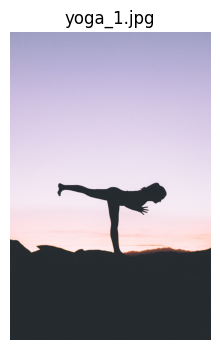

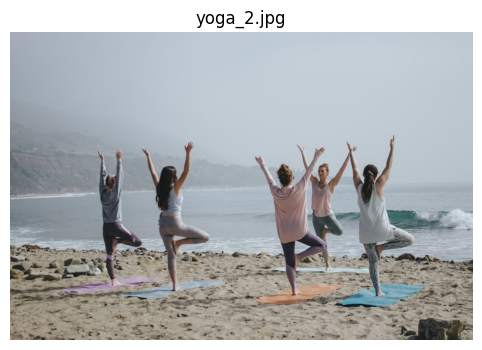

In [37]:
image_urls = [
    (
        'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/yoga_1.jpg',
        'yoga_1.jpg'
    ),
    (
        'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/yoga_2.jpg',
        'yoga_2.jpg'
    ),
]
image_paths = download_images(image_urls, plot_images=True)


0: 640x640 1 person, 47.6ms
1: 640x640 5 persons, 47.6ms
Speed: 1.6ms preprocess, 47.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


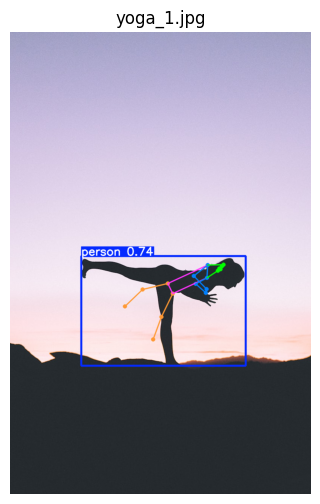

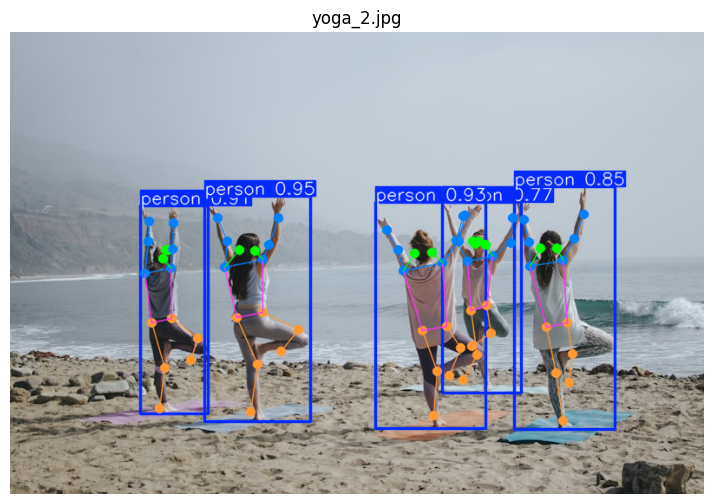

In [38]:
# Run the model
results = model(image_paths)

# Show results
for i, r in enumerate(results):
    # Extract the original and annotated images
    original_img = r.orig_img[..., ::-1]
    annotated_image_bgr = r.plot()  # BGR numpy array of predictions
    annotated_image_rgb = annotated_image_bgr[..., ::-1]  # Convert BGR to RGB

    # Plot the annotated image
    plt.figure(figsize=(10, 6))
    plt.imshow(annotated_image_rgb) # RGB PIL image
    plt.axis('off')
    plt.title(image_paths[i])
    plt.show()

## Extra: Detecting Small Objects with SAHI

Standard YOLO resizes the whole image to a fixed size (e.g. 640×640) before detecting. In a large, crowded scene — like the traffic image, full of distant motorbikes and people — small far-away objects shrink to just a few pixels and get missed.

**SAHI (Slicing Aided Hyper Inference)** fixes this: it cuts the image into **overlapping tiles**, runs YOLO on each tile (where the small objects are now relatively large), and **merges** all detections back together, using NMS to drop duplicates in the overlaps.

*Intuition: instead of squinting at the whole scene at once, look at it tile by tile with a magnifying glass, then combine what you found.*

SAHI is a separate library with native support for Ultralytics YOLO. Install it with `%pip install sahi`. On the traffic image you should see it detect **many more** objects than standard inference.

In [40]:
%pip install sahi
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

# Standard whole-image detection, for reference
standard = YOLO('yolo11m.pt')('traffic.jpg', conf=0.25, verbose=False)
print(f'Standard YOLO: {len(standard[0].boxes)} objects')

# Wrap the same YOLO11 model for SAHI and run sliced (tiled) inference
detection_model = AutoDetectionModel.from_pretrained(
    model_type='ultralytics',
    model_path='yolo11n.pt',
    confidence_threshold=0.25,
)
result = get_sliced_prediction(
    'traffic.jpg',
    detection_model,
    slice_height=256,
    slice_width=256,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
)
print(f'SAHI sliced:   {len(result.object_prediction_list)} objects')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 14.1 MB/s eta 0:00:00
Standard YOLO: 17 objects
Performing prediction on 24 slices.
SAHI sliced:   39 objects


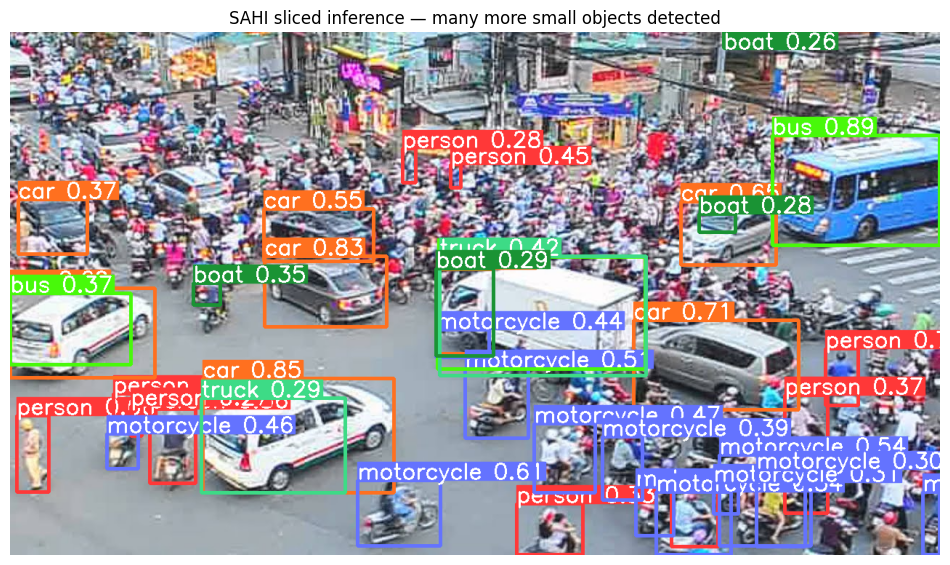

In [41]:
# Export SAHI's annotated image and display it
result.export_visuals(export_dir='sahi_output/')

sahi_img = cv2.cvtColor(cv2.imread('sahi_output/prediction_visual.png'), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 8))
plt.imshow(sahi_img)
plt.axis('off')
plt.title('SAHI sliced inference — many more small objects detected')
plt.show()